# Lab 07 Data Preprocessing

## Overview

In this lab, we'll continue building on our data understanding by addressing issues that prevent meaningful analysis — namely, data quality and structure.

- Handle missing values and inconsistent formats. 
- Identify and manage outliers. 
- Create features that better reflect business behavior. 

This class:
- Scale our numerical data to prevent features with larger scales from dominating the algorithm. 
- Encode the necessary features. 

Essentially, ensure our data is suitable for clustering and other modeling tasks. Without preprocessing, any clustering results would be unreliable or misleading. Clean, consistent data is essential for drawing valid business insights.

In [16]:
# Remember: library imports are ALWAYS at the top of the script, no exceptions!
import sqlite3
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

from itertools import product
from scipy.stats import skewnorm

from datetime import datetime
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

# Setting seaborn style
sns.set_style()

# Context
The data we will be using through the pratical classes comes from a small relational database whose schema can be seen below:
![alt text](../figures/schema.png "Relation database schema")

# Reading the Data

In [17]:
# path to database
my_path = os.path.join("..", "data", "datamining.db")

# connect to the database
conn = sqlite3.connect(my_path)

# the query
query = """
select
    age, 
    income, 
    frq, 
    rcn, 
    mnt, 
    clothes, 
    kitchen, 
    small_appliances, 
    toys, 
    house_keeping,
    dependents, 
    per_net_purchase,
    g.gender, 
    e.education, 
    m.status, 
    r.description
from customers as c
    join genders as g on g.id = c.gender_id
    join education_levels as e on e.id = c.education_id
    join marital_status as m on m.id = c.marital_status_id
    join recommendations as r on r.id = c.recommendation_id
order by c.id;
"""

df = pd.read_sql_query(query, conn)

## Make a copy of your original dataset

In [18]:
df_original = df.copy()

# Metadata
- *id* - The unique identifier of the customer
- *age* - The year of birht of the customer
- *income* - The income of the customer
- *frq* - Frequency: number of purchases made by the customer
- *rcn* - Recency: number of days since last customer purchase
- *mnt* - Monetary: amount of € spent by the customer in purchases
- *clothes* - Number of clothes items purchased by the customer
- *kitchen* - Number of kitchen items purchased by the customer
- *small_appliances* - Number of small_appliances items purchased by the customer
- *toys* - Number of toys items purchased by the customer
- *house_keeping* - Number of house_keeping items purchased by the customer
- *dependents* - Binary. Whether or not the customer has dependents
- *per_net_purchase* - Percentage of purchases made online
- *education* - Education level of the customer
- *status* - Marital status of the customer
- *gender* - Gender of the customer
- *description* - Last customer's recommendation description

## Problems:
- Duplicates?
- Data types?
- Missing values?
- Strange values?
- Descriptive statistics?

### Take a closer look and point out possible problems:

(hint: a missing values in pandas is represented with a NaN value)

### Replicating modifications from previous notebooks

In [19]:
# replace "" by nans
df.replace("", np.nan, inplace=True)

# count of missing values
df.isna().sum()

C:\Users\X1605\AppData\Local\Temp\ipykernel_28888\3385904135.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace("", np.nan, inplace=True)


age                   0
income               46
frq                   0
rcn                   0
mnt                   0
clothes               0
kitchen               0
small_appliances      0
toys                  0
house_keeping         0
dependents          282
per_net_purchase      0
gender                0
education            47
status              177
description           0
dtype: int64

In [20]:
# fix wrong dtypes
df.dependents = df.dependents.astype("boolean")  # converting to "boolean" over "bool" allows preservation of NaNs

In [21]:
#Define metric and non-metric features. Why?
non_metric_features = ["education", "status", "gender", "dependents", "description"]
metric_features = df.columns.drop(non_metric_features).to_list()

# Data Preprocessing from Lab  06

In [22]:
## Filling missing values with measure of central tendency 
medians = df[metric_features].median()
modes = df[non_metric_features].mode().loc[0]
df[metric_features] = df[metric_features].fillna(medians)
df[non_metric_features] = df[non_metric_features].fillna(modes)

df.isna().sum()

age                 0
income              0
frq                 0
rcn                 0
mnt                 0
clothes             0
kitchen             0
small_appliances    0
toys                0
house_keeping       0
dependents          0
per_net_purchase    0
gender              0
education           0
status              0
description         0
dtype: int64

In [23]:
## Outlier removal
# This may vary from session to session, and is prone to varying interpretations.
# A simple example is provided below:

# ( df['feature1']<= limit1 ) & ( df['feature2']<= limit2 ) ...


filters_man = (
    (df['house_keeping']<=50)
    &
    (df['kitchen']<=40)
    &
    (df['toys']<=35)
    &
    (df['education']!='OldSchool')
)

df_man = df[filters_man]

In [24]:
## Applying the manual filtering to the original dataframe
df = df_man.copy()
print('Percentage of data kept after removing outliers:', 100*np.round(df.shape[0] / df_original.shape[0], 4))

Percentage of data kept after removing outliers: 97.99


In [25]:
# ## Winsorizing (outlier threshold value)
print((df['rcn']>100).value_counts())
rcn_t = df['rcn'].copy()
rcn_t.loc[rcn_t>100] = 100

df['rcn'] = rcn_t

rcn
False    8437
True      380
Name: count, dtype: int64


In [26]:
# Feature engineering 
#creation of new features

df['birth_year'] = df['age']
df['age'] = 2024 - df['birth_year']
df['spent_online'] = df['per_net_purchase']*df['mnt']/100

metric_features.append('spent_online')
metric_features.append('birth_year')


In [27]:
# Feature selection decicions
## RUN THIS CELL ONLY ONCE!!!!

metric_features.remove("mnt")
metric_features.remove("age")
metric_features.remove("birth_year")

# You can also drop the features from the df
# But sometimes they may be useful for cluster profiling later

# df.drop(..., inplace=True)

## Data Normalization / Scaling

In [28]:
# Remember our original data

df.describe().round(2)

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,per_net_purchase,birth_year,spent_online
count,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00,8817.00
mean,58.34,70534.39,19.99,52.22,630.16,51.18,6.78,28.67,6.58,6.76,42.24,1965.66,178.38
std,17.08,27246.78,10.92,30.10,647.83,22.98,7.31,12.60,6.90,7.54,18.48,17.08,168.58
min,28.00,10000.00,3.00,0.00,6.00,1.00,0.00,1.00,0.00,0.00,4.00,1936.00,2.73
25%,44.00,48842.00,10.00,26.00,64.00,34.00,2.00,19.00,2.00,2.00,27.00,1951.00,34.65
50%,58.00,70388.00,18.00,53.00,387.00,52.00,4.00,28.00,4.00,4.00,45.00,1966.00,140.00
75%,73.00,92413.00,28.00,78.00,1079.00,70.00,9.00,37.00,9.00,9.00,57.00,1980.00,265.10
max,88.00,140628.00,59.00,100.00,3052.00,99.00,40.00,74.00,35.00,50.00,88.00,1996.00,1416.24


### **MinMax Scaling**

Transforms values to be between [0,1]

$$
x' = \frac{x - min(X)}{max(X) - min(X)}
$$

<br>
<br>

where:
- x$ is an original value
- $x'$ is the normalized value

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

In [29]:
## Let's look at an example:

demo_ages = pd.DataFrame({"Age": [14, 24, 22, 18, 18, 26, 11, 23, 13, 12]})
demo_ages

,Age
0,14
1,24
2,22
3,18
4,18
5,26
6,11
7,23
8,13
9,12


#### How to MinMax Scaling with Python/Pandas?


( demo_ages - min(demo_ages) ) / max(demo_ages) - min(demo_ages)


#### Exercise `1`: Scale the `age` column with MinMax 

In [30]:
min_age = demo_ages["Age"] # finish this line
max_age = demo_ages["Age"] # finish this line

mm_age = None # finish this line


(This is not showing all rows)


Age (Orig) | Formula        | Result
-----------|----------------|-------
14         | (14 - 11) / 15 | 0.2
24         | (24 - 11) / 15 | 0.86666667
26         | (26 - 11) / 15 | 1
11         | (11 - 11) / 15 | 0






#### Exercise `2`: Use MinMaxScaler from sklearn.preprocessing

In [31]:
# sklearn makes it even easier:

demo_ages["Age_minmax"] = MinMaxScaler()# finish this line

demo_ages

,Age,Age_minmax
0,14,MinMaxScaler()
1,24,MinMaxScaler()
2,22,MinMaxScaler()
3,18,MinMaxScaler()
4,18,MinMaxScaler()
5,26,MinMaxScaler()
6,11,MinMaxScaler()
7,23,MinMaxScaler()
8,13,MinMaxScaler()
9,12,MinMaxScaler()


#### Exercise `3`: Apply MinMaxScaler to the dataset

In [32]:
df_minmax = df.copy()

In [33]:
# Use MinMaxScaler to scale the data
mm_scaler = MinMaxScaler()
mm_scaled_feat = None # finish this line
mm_scaled_feat

In [34]:
# See what the fit method is doing (notice the trailing underscore):
# print("Parameters fitted:\n")
# pd.DataFrame([mm_scaler.data_min_, mm_scaler.data_max_], columns=metric_features, index=['min','max'])

In [35]:
## Replace original metric_features values with mm_scaled_feat values
df_minmax[metric_features] = mm_scaled_feat

In [36]:
# Checking max and min of minmaxed variables
df_minmax[metric_features].describe().T.round(2)

,count,unique,top,freq
income,0,0,NaN,NaN
frq,0,0,NaN,NaN
rcn,0,0,NaN,NaN
clothes,0,0,NaN,NaN
kitchen,0,0,NaN,NaN
small_appliances,0,0,NaN,NaN
toys,0,0,NaN,NaN
house_keeping,0,0,NaN,NaN
per_net_purchase,0,0,NaN,NaN
spent_online,0,0,NaN,NaN


In [37]:
df_minmax[metric_features].head()

,income,frq,rcn,clothes,kitchen,small_appliances,toys,house_keeping,per_net_purchase,spent_online
0,None,None,None,None,None,None,None,None,None,None
1,None,None,None,None,None,None,None,None,None,None
2,None,None,None,None,None,None,None,None,None,None
3,None,None,None,None,None,None,None,None,None,None
4,None,None,None,None,None,None,None,None,None,None


In [38]:
df[metric_features].head()

,income,frq,rcn,clothes,kitchen,small_appliances,toys,house_keeping,per_net_purchase,spent_online
0,90782.0,33,66,37,5,44,10,3,19,266.38
1,113023.0,32,6,55,1,38,4,2,9,138.33
2,28344.0,11,69,32,19,24,1,24,59,25.96
3,93571.0,26,10,60,10,19,6,5,35,310.80
4,91852.0,31,26,59,5,28,4,4,34,386.92


### **Standard Scaling**

AKA Z-Score Scaling

Standardize features by removing the mean and scaling to unit variance.

The standard score of a sample x is calculated as:

$$
z = \frac{x - \mu}{\sigma}
$$

where:

- $u$ is the mean of the training samples,
- $\sigma$ is the standard deviation of the training samples

The standard deviation $\sigma$ is given by:

$$
\sigma = \sqrt{\frac{\sum_{i=1}^{N} (x_i - \bar{x})^2}{N - \text{ddof}}}
$$

where:

- $x_i$ = each data point  
- $\bar{x}$ = mean of the data  
- $N$ = number of observations  
- $\text{ddof}$ = delta degrees of freedom  
    - ddof = 0 in population 
    - ddof = 1 in sample

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

#### `Intuition exercise`

If a original feature had:

- Mean (𝜇) = 40
- Standard deviation (𝜎) = 10

Your data was [30, 40, 50]

What will be the values scaled with z-score ? 

In [39]:
## Let's see the age demo again

demo_ages


,Age,Age_minmax
0,14,MinMaxScaler()
1,24,MinMaxScaler()
2,22,MinMaxScaler()
3,18,MinMaxScaler()
4,18,MinMaxScaler()
5,26,MinMaxScaler()
6,11,MinMaxScaler()
7,23,MinMaxScaler()
8,13,MinMaxScaler()
9,12,MinMaxScaler()


 #### How to do Standard Scaling with Python/Pandas?

 ( demo_ages - mean (demo_ages) ) /  std (demo_ages)

In [41]:
## u = mean of age
## s = std of age

mean_age = demo_ages["Age"].mean()
std_age  = demo_ages["Age"].std(ddof = 0) # to match sklearn implementation of std


In [58]:
(demo_ages["Age"] - mean_age) / std_age

0   -0.793614
1    1.142031
2    0.754902
3   -0.019356
4   -0.019356
5    1.529160
6   -1.374308
7    0.948466
8   -0.987179
9   -1.180743
Name: Age, dtype: float64

In [59]:
# Or use sklearn:

demo_ages["Age_standard"] = StandardScaler().fit_transform(demo_ages[["Age"]])

demo_ages

,Age,Age_minmax,Age_standard
0,14,MinMaxScaler(),-0.793614
1,24,MinMaxScaler(),1.142031
2,22,MinMaxScaler(),0.754902
3,18,MinMaxScaler(),-0.019356
4,18,MinMaxScaler(),-0.019356
5,26,MinMaxScaler(),1.529160
6,11,MinMaxScaler(),-1.374308
7,23,MinMaxScaler(),0.948466
8,13,MinMaxScaler(),-0.987179
9,12,MinMaxScaler(),-1.180743


In [60]:
demo_ages.describe().round(2)

,Age,Age_standard
count,10.00,10.00
mean,18.10,-0.00
std,5.45,1.05
min,11.00,-1.37
25%,13.25,-0.94
50%,18.00,-0.02
75%,22.75,0.90
max,26.00,1.53


#### Exercise `4`: Apply StandardScaler to the dataset

In [61]:
df_standard = df.copy()

In [62]:
ss_scaler = None # finish this line
ss_scaled_feat = None # finish this line
ss_scaled_feat

In [64]:
# See what the fit method is doing (notice the trailing underscore):
print("Parameters fitted:\n")
# pd.DataFrame([ss_scaler.mean_, np.sqrt(ss_scaler.var_)], columns=metric_features, index=['mean','std'])

Parameters fitted:



In [65]:
df_standard[metric_features] = ss_scaled_feat
df_standard.head()

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description,birth_year,spent_online
0,78,None,None,None,1402,None,None,None,None,None,False,None,M,Graduation,Together,Take my money!!,1946,None
1,88,None,None,None,1537,None,None,None,None,None,False,None,F,PhD,Divorced,Take my money!!,1936,None
2,34,None,None,None,44,None,None,None,None,None,True,None,M,Graduation,Married,Kind of OK,1990,None
3,69,None,None,None,888,None,None,None,None,None,True,None,F,Master,Married,OK nice!,1955,None
4,69,None,None,None,1138,None,None,None,None,None,True,None,F,Graduation,Together,Take my money!!,1955,None


In [66]:
# Checking mean and variance of standardized variables
df_standard[metric_features].describe().round(2)

,income,frq,rcn,clothes,kitchen,small_appliances,toys,house_keeping,per_net_purchase,spent_online
count,0,0,0,0,0,0,0,0,0,0
unique,0,0,0,0,0,0,0,0,0,0
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### `Intuition exercise` 
- What if we had a training and test set? 
- Should we fit a Scaler in both? 
- What about other Sklearn objects?

## Compare MinMaxScaler vs StandardScaler vs Original data

### Boxplots

ValueError: List of boxplot statistics and `positions` values must have same the length

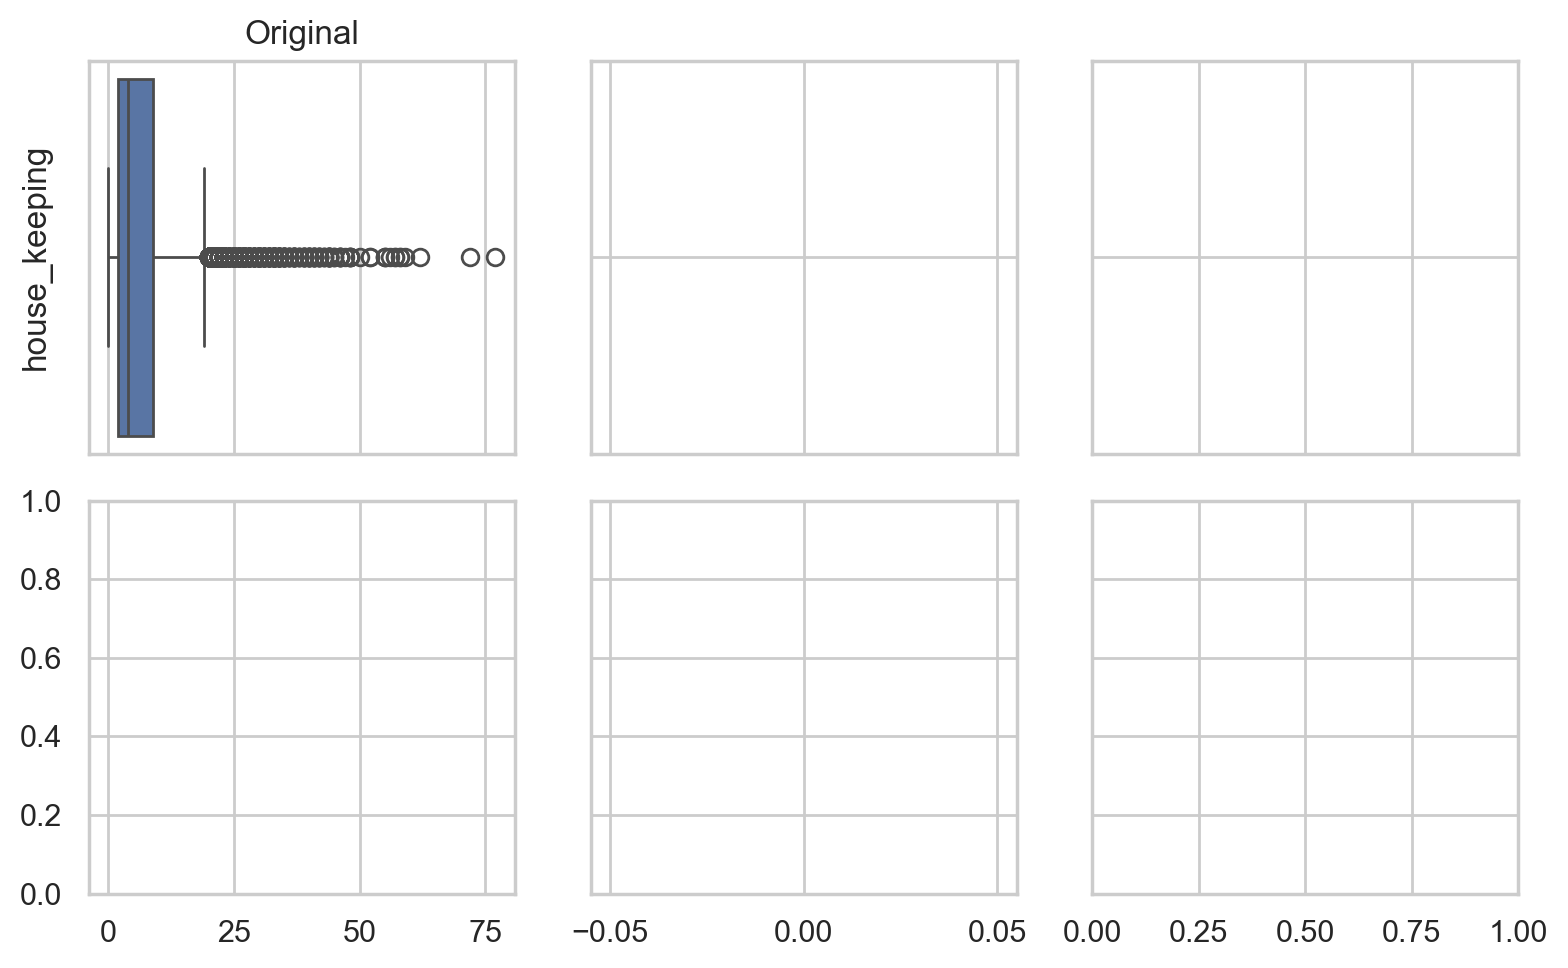

In [ ]:

sns.set_style('whitegrid')
fig, axes = plt.subplots(2,3, figsize=(8,5), tight_layout=True, sharex='col', sharey='row')

bp_feat_l = 'house_keeping'

sns.boxplot(df_original, x=bp_feat_l, ax=axes[0][0], width=.4)
axes[0][0].set_title('Original')
axes[0][0].set_ylabel(bp_feat_l)

sns.boxplot(df_minmax, x=bp_feat_l, ax=axes[0][1], width=.4)
axes[0][1].set_title('MinMaxScaler()')

sns.boxplot(df_standard, x=bp_feat_l, ax=axes[0][2], width=.4)
axes[0][2].set_title('StandardScaler()')



bp_feat_r = 'income'

sns.boxplot(df_original, x=bp_feat_r, ax=axes[1][0], width=.4)
axes[1][0].set_ylabel(bp_feat_r)

sns.boxplot(df_minmax, x=bp_feat_r, ax=axes[1][1], width=.4)

sns.boxplot(df_standard, x=bp_feat_r, ax=axes[1][2], width=.4)


axes[1][0].set_xlabel(None)
axes[1][1].set_xlabel(None)
axes[1][2].set_xlabel(None)

fig.suptitle('Boxplots: "{}" and "{}"'.format(bp_feat_l, bp_feat_r))
plt.show()

In [ ]:
sns.set_style('white')

fig, axes = plt.subplots(3,1, figsize=(8,5), tight_layout=True,)

sns.boxplot(df, x=bp_feat_l, ax=axes[2], width=.4)
sns.boxplot(df_minmax, x=bp_feat_l, ax=axes[1], width=.4)
sns.boxplot(df_standard, x=bp_feat_l, ax=axes[0], width=.4)

axes[0].set_title("standard")
axes[0].set_xlabel(None)
axes[1].set_title("mm")
axes[1].set_xlabel(None)
axes[2].set_title("origi")
axes[2].set_xlabel(None)

plt.suptitle('Boxplots: "{}"'.format(bp_feat_l))



### Histograms

What about histograms?

- Visualize histograms here, compare the shapes of the original distribution with the MinMaxScaler and StandardScaler results.

In [ ]:
sns.set_style('whitegrid')

# Create subplots with 3 rows, 1 column:
fig, axes = plt.subplots(3,1, 
                         figsize=(5,5), tight_layout=True)

# Which feature do you want to visualize?
hp_feat = 'house_keeping'

# common function args for histplot
hp_args = dict(x=hp_feat, bins=15)


sns.histplot(df_original, ax=axes[0], **hp_args)
axes[0].set_title('{}: Original'.format(hp_feat))
axes[0].set_xlabel(None)

sns.histplot(df_minmax, ax=axes[1], **hp_args)
axes[1].set_title('{}: MinMaxScaler()'.format(hp_feat))
axes[1].set_xlabel(None)

sns.histplot(df_standard, ax=axes[2], **hp_args)
axes[2].set_title('{}: StandardScaler()'.format(hp_feat))
axes[2].set_xlabel(None)


plt.show()

#### Keep StandardScaler

In [ ]:
df = df_standard.copy()

## **One-hot encoding**

In [42]:
df_ohc = df.copy()

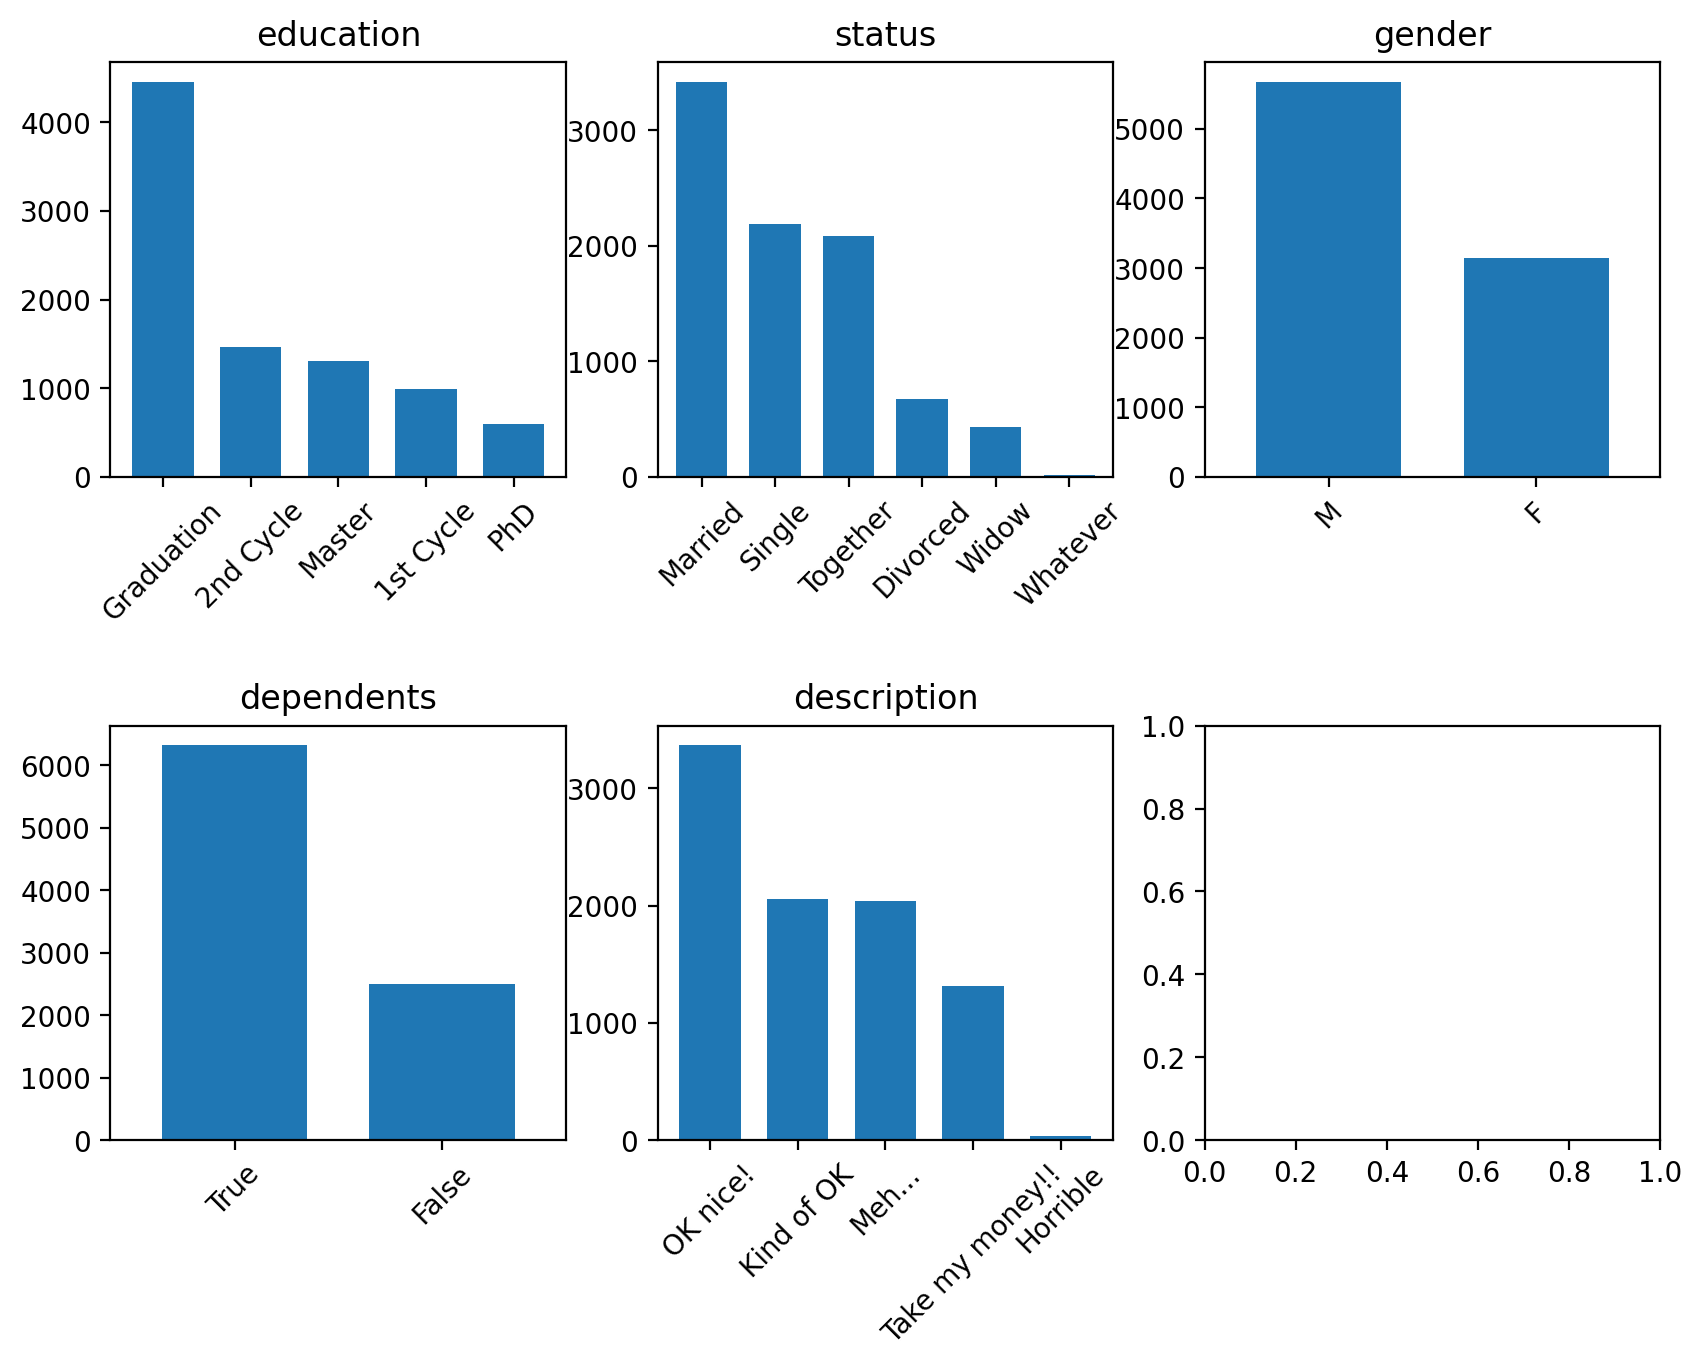

In [43]:
df['dependents'] = df['dependents'].fillna(False)

fig, axes = plt.subplots(
    2,
    ceil(len(non_metric_features) / 2),
    figsize=(10,7))

for ax, feat in zip(axes.flatten(), non_metric_features):
    df[feat].value_counts().plot.bar(ax=ax, width=.7)
    ax.set_title(feat)
    ax.set_xlabel(None)
    ax.set_ylabel(None) 
    ax.tick_params(axis='x', rotation=45)

plt.subplots_adjust(hspace=0.6)
plt.show()

First let's remove status=Whatever

In [44]:
df_ohc.loc[df_ohc['status'] == 'Whatever', 'status'] = df['status'].mode()[0]

In [45]:
# Use OneHotEncoder to encode the categorical features. Get feature names and create a DataFrame 
# with the one-hot encoded categorical features (pass feature names)
ohc = OneHotEncoder(sparse_output=False, drop="first") #sparse_output=False outputs a numpy array, not a sparse matrix
ohc_feat = ohc.fit_transform(df_ohc[non_metric_features])
ohc_feat_names = ohc.get_feature_names_out()


In [47]:
ohc_df = pd.DataFrame(ohc_feat, index=df_ohc.index, columns=ohc_feat_names)  # Why the index=df_ohc.index?
ohc_df

,education_2nd Cycle,education_Graduation,education_Master,education_PhD,status_Married,status_Single,status_Together,status_Widow,gender_M,dependents_1.0,description_Kind of OK,description_Meh...,description_OK nice!,description_Take my money!!
0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8992,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
8993,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8994,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
8995,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [48]:
# Reassigning df to contain ohc variables
df_ohc = pd.concat([df_ohc, ohc_df], axis=1)
df_ohc.head()

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,...,status_Married,status_Single,status_Together,status_Widow,gender_M,dependents_1.0,description_Kind of OK,description_Meh...,description_OK nice!,description_Take my money!!
0,78,90782.0,33,66,1402,37,5,44,10,3,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,88,113023.0,32,6,1537,55,1,38,4,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,34,28344.0,11,69,44,32,19,24,1,24,...,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
3,69,93571.0,26,10,888,60,10,19,6,5,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,69,91852.0,31,26,1138,59,5,28,4,4,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [49]:
df = df_ohc.copy()

In [50]:
list(df.columns)

['age',
 'income',
 'frq',
 'rcn',
 'mnt',
 'clothes',
 'kitchen',
 'small_appliances',
 'toys',
 'house_keeping',
 'dependents',
 'per_net_purchase',
 'gender',
 'education',
 'status',
 'description',
 'birth_year',
 'spent_online',
 'education_2nd Cycle',
 'education_Graduation',
 'education_Master',
 'education_PhD',
 'status_Married',
 'status_Single',
 'status_Together',
 'status_Widow',
 'gender_M',
 'dependents_1.0',
 'description_Kind of OK',
 'description_Meh...',
 'description_OK nice!',
 'description_Take my money!!']

In [ ]:
# You can also choose to drop the original non_metric_features from your df
# df.drop(columns=non_metric_features)

### Rename OHE columns

In [ ]:
## Rename OHE columns from "feature_val_a" to "oh_feature_val_a"
## e.g. status_Widow to oh_status_Widow
## We do this to be able to distinguish the OHE columns more easily later

## Assemble OHE columns and their new column names
rename_ohe_cols = {}

for i in non_metric_features:
    for j in df.columns[df.columns.str.startswith(i)].to_list() :
        if j not in non_metric_features:
            rename_ohe_cols[j] = 'oh_' + j

df.rename(columns=rename_ohe_cols, inplace=True)


In [ ]:
df

In [ ]:
list(df.columns)

## Redo data exploration

Check if the data looks the way you expect it to. 

- Have you missed some outliers? 
- Are there still missing values?
- Is the data normalized?

This is an iterative process. It is likely you will change your preprocessing steps frequently throughout your group work.

#### A tool to assist you through your exploratory data analysis

Optionally, you may use `pandas-profiling` in your data analysis. 

Remember, although this tool provides excelent insights about the data you're working with, it is not enough to perform a proper analysis.

In [ ]:

# ProfileReport(
#     df,
#     title='Tugas Customer Data Preprocessed',
#     correlations={
#         "pearson": {"calculate": True},
#         "spearman": {"calculate": False},
#         "kendall": {"calculate": False},
#         "phi_k": {"calculate": False},
#         "cramers": {"calculate": False},
#     },
# )